# Eje 7d — Comparación de todos los modelos

Derivados Financieros · QUANt UCEMA · **Pricing avanzado**

Misma opción de juguete: precio nativo vs QuantLib, **tiempo de máquina**, y guía
de **cuándo usar cada modelo**.

**Plan**
1. Parámetros fijos
2. Benchmark europeo (nativo + QL)
3. Americanas
4. Tabla pros / contras
5. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from Codigo.pricing import (
    _QL_AVAILABLE,
    opcion_europea_bs, opcion_europea_bs_ql,
    opcion_europea_bin, opcion_europea_bin_ql,
    opcion_europea_bin_c, opcion_europea_bin_c_ql,
    opcion_europea_mc, opcion_europea_mc_ql,
    opcion_europea_mc_fv, opcion_europea_mc_fv_ql,
    opcion_europea_fd, opcion_europea_fd_ql,
    opcion_americana_bs, opcion_americana_bs_ql,
    opcion_americana_bin, opcion_americana_bin_ql,
    opcion_americana_fd, opcion_americana_fd_ql,
    opcion_americana_mc, opcion_americana_mc_ql,
)
assert _QL_AVAILABLE
np.random.seed(0)

## 2) Parámetros

In [3]:
tipo = "C"
S, K, T = 100.0, 100.0, 1.0
r, sigma, div = 0.05, 0.25, 0.0
pasos_bin = 200
pasos_mc = 20_000
M_fd = 120
print(dict(tipo=tipo, S=S, K=K, T=T, r=r, sigma=sigma, div=div,
           pasos_bin=pasos_bin, pasos_mc=pasos_mc, M_fd=M_fd))

{'tipo': 'C', 'S': 100.0, 'K': 100.0, 'T': 1.0, 'r': 0.05, 'sigma': 0.25, 'div': 0.0, 'pasos_bin': 200, 'pasos_mc': 20000, 'M_fd': 120}


## 3) Benchmark europeos

In [4]:
def timed(fn, *args, repeats=3):
    t = timeit.repeat(lambda: fn(*args), number=1, repeat=repeats)
    # recalcular una vez el precio (tras el timing)
    val = fn(*args)
    return val, 1000.0 * min(t)  # ms

euro = []
specs = [
    ("BS", opcion_europea_bs, opcion_europea_bs_ql, (tipo,S,K,T,r,sigma,div)),
    ("Bin CRR", opcion_europea_bin, opcion_europea_bin_ql, (tipo,S,K,T,r,sigma,div,pasos_bin)),
    ("Bin cerrado", opcion_europea_bin_c, opcion_europea_bin_c_ql, (tipo,S,K,T,r,sigma,div,pasos_bin)),
    ("MC", opcion_europea_mc, opcion_europea_mc_ql, (tipo,S,K,T,r,sigma,div,pasos_mc)),
    ("MC antithetic", opcion_europea_mc_fv, opcion_europea_mc_fv_ql, (tipo,S,K,T,r,sigma,div,pasos_mc)),
    ("FD", opcion_europea_fd, opcion_europea_fd_ql, (tipo,S,K,T,r,sigma,div,M_fd)),
]
for name, fn, fn_ql, args in specs:
    v, ms = timed(fn, *args)
    vq, msq = timed(fn_ql, *args)
    euro.append({
        "modelo": name,
        "precio_nativo": v,
        "precio_QL": vq,
        "diff": v - vq,
        "ms_nativo": ms,
        "ms_QL": msq,
    })
df_euro = pd.DataFrame(euro)
df_euro.round({"precio_nativo": 6, "precio_QL": 6, "diff": 6, "ms_nativo": 3, "ms_QL": 3})

,modelo,precio_nativo,precio_QL,diff,ms_nativo,ms_QL
0,BS,12.335999,12.335999,0.000000,0.166,0.107
1,Bin CRR,12.323646,12.323367,0.000280,1.311,0.415
2,Bin cerrado,12.323646,12.323367,0.000280,0.802,0.447
3,MC,12.207142,12.340836,-0.133694,1.326,208.095
4,MC antithetic,12.269489,12.338189,-0.068700,1.688,365.013
5,FD,12.324710,12.341511,-0.016801,102.641,49.974


## 4) Americanas (put ATM — ahí importa early exercise)

In [5]:
tipo_a = "P"
ame = []
specs_a = [
    ("BAW / approx", opcion_americana_bs, opcion_americana_bs_ql, (tipo_a,S,K,T,r,sigma,div)),
    ("Bin CRR", opcion_americana_bin, opcion_americana_bin_ql, (tipo_a,S,K,T,r,sigma,div,pasos_bin)),
    ("FD", opcion_americana_fd, opcion_americana_fd_ql, (tipo_a,S,K,T,r,sigma,div,M_fd)),
    ("MC LSM", opcion_americana_mc, opcion_americana_mc_ql, (tipo_a,S,K,T,r,sigma,div,5_000)),
]
for name, fn, fn_ql, args in specs_a:
    v, ms = timed(fn, *args, repeats=2)
    vq, msq = timed(fn_ql, *args, repeats=2)
    ame.append({
        "modelo": name,
        "precio_nativo": v,
        "precio_QL": vq,
        "diff": v - vq,
        "ms_nativo": ms,
        "ms_QL": msq,
    })
df_ame = pd.DataFrame(ame)
print("Put americana ATM")
df_ame.round({"precio_nativo": 6, "precio_QL": 6, "diff": 6, "ms_nativo": 3, "ms_QL": 3})

Put americana ATM


,modelo,precio_nativo,precio_QL,diff,ms_nativo,ms_QL
0,BAW / approx,8.000112,7.982520,0.017592,2.008,0.133
1,Bin CRR,7.967099,7.969216,-0.002117,34.520,1.198
2,FD,8.100559,7.972399,0.128161,292.890,63.039
3,MC LSM,7.864918,8.005192,-0.140274,20.146,75.464


## 5) Barras de tiempo (europeos)

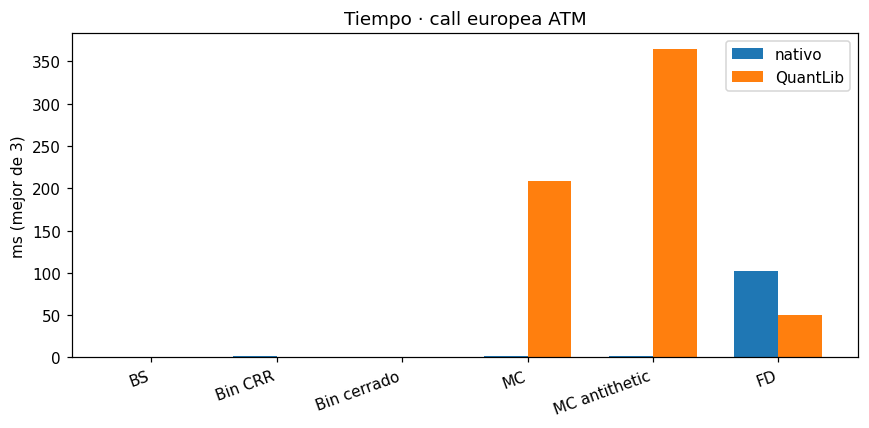

In [6]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=110)
x = np.arange(len(df_euro))
w = 0.35
ax.bar(x - w/2, df_euro["ms_nativo"], w, label="nativo")
ax.bar(x + w/2, df_euro["ms_QL"], w, label="QuantLib")
ax.set_xticks(x); ax.set_xticklabels(df_euro["modelo"], rotation=20, ha="right")
ax.set_ylabel("ms (mejor de 3)"); ax.set_title("Tiempo · call europea ATM")
ax.legend(); plt.tight_layout(); plt.show()

## 6) Pros / contras y cuándo usar cada uno

| Modelo | Pros | Contras | Conviene cuando… |
|--------|------|---------|------------------|
| **BS / BAW** | Exacto (euro) / cerrado; instantáneo; griegas analíticas | No path-dependent; BAW es aproximación | Vanilla europea; screening rápido; IV |
| **Binomial CRR** | Didáctico; americanas naturales; intuitivo | Converge lento; $O(N^2)$ | Americanas; teaching; N moderado |
| **Binomial cerrado** | Más rápido que árbol explícito | Solo europeo | Check rápido vs BS |
| **Monte Carlo** | Flexible (barreras, asiáticas, baskets) | Ruido $1/\sqrt{N}$; americanas difíciles (LSM) | Exóticos / muchos factores |
| **MC antithetic** | Menos varianza, casi mismo costo | No elimina el sesgo de discretización | Misma idea que MC, más eficiente |
| **Diferencias finitas** | PDE + americanas; superficie $V(S,t)$ | Grilla; dimensión maldición (>2–3 factores) | Americanas / PDE; 1–2 factores |
| **QuantLib** | Engines industriales, mantenimiento, exóticos | API verbosa; dependencia externa | Producción, validación, engines avanzados |

Regla práctica del curso:
1. ¿Europea vanilla? → **BS**.
2. ¿Americana equity? → **binomial** o **FD** (validar con QL).
3. ¿Path-dependent / multi-asset? → **MC** (+ QL si hay engine).
4. ¿Necesitás auditar? → mismo contrato en **nativo y `*_ql`**.

## Resumen

- Los wrappers `*_ql` permiten A/B testing sin reescribir firmas.
- Los tiempos absolutos dependen de la máquina; lo útil es el **orden de magnitud** relativo.
- Elegí el modelo por **estructura del producto**, no solo por el precio.

**Ejercicio:** repetí el benchmark con put europea OTM ($K=80$) y mirá si el ranking de tiempos cambia.

**Siguiente:** **08a** — Griegas.